# Section 1: Data Selection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

pregnancy = pd.read_csv("..\\data\\Pregnancy.csv")
pregnancy["Risk Level"] = pregnancy["Risk Level"].map({
    "Low": 0,
    "High": 1
})

### Dataset shape

**Based on the Data Understanding analysis, which columns had the strongest relationship with Risk Level? List them in order of relationship strength.**

- Preexisting Diabetes => 0.68
- Mental Health => 0.63
- BS => 0.59
- Previous Complications => 0.54
- BMI => 0.52
- Heart Rate => 0.48
- Gestational Diabetes => 0.44
- Diastolic => 0.33
- Systolic BP => 0.29
- Body Temp => 0.21
- Age => 0.19

### Variable types and conceptual categories

**Complete the following table:**

| Feature | Business Importance | Data Importance |
|---|---|---|

| Feature | Business Importance | Data Importance |
|---|---|---|
| Preexisting Diabetes | High | High (0.69) |
| Mental Health | High | High (0.64) |
| Blood Sugar | High | High (0.59) |
| Previous Complications | High | High (0.54) |
| BMI | High | High (0.52) |
| Heart Rate | Medium | Medium (0.48) |
| Gestational Diabetes | High | High (possible data leakage) |
| Diastolic BP | High | Medium (0.33) |
| Systolic BP | High | Medium (0.29) |
| Body Temp | Low | Low (0.21) |
| Age | High | Low (0.20) |

### Clinical description of variables

**Identify at least three features that are not useful for modeling or carry risk.**

- Heart Rate
- Body Temp
- Age => Convert to grouping

### Measurement units and value ranges

**Build a new version of the dataset containing only the selected features (`selected_df`), and compare the number of features before/after.**

### Final no-leakage feature set

The deployable no-leakage model uses the following feature set because each variable is available at a realistic prenatal screening point and is not determined by the diagnosis process itself: `Age`, `Systolic BP`, `Diastolic`, `BS`, `BMI`, `Previous Complications`, `Preexisting Diabetes`, `Mental Health`, `Heart Rate`, `age_group`, `is_hypertensive`, and `pulse_pressure`.

The excluded variables are kept only for comparison because they are either leakage-prone or not available at prediction time: `Body Temp`, `Gestational Diabetes`, `bmi_category`, `risk_factor_count`, `bp_level`, and other engineered features derived from the same pregnancy context.


### Data flow and naming

The data flow is intentionally explicit: raw/selected dataset -> train/test split -> training data -> test data -> validation from training -> final test evaluation. `selected_df` is used as a working reference to the selected feature set, while `train_df` and `test_df` remain the authoritative split for modeling and evaluation. The train/test split is created before preprocessing, validation, and threshold selection, and the final test set is reserved for the final evaluation stage.


In [2]:
selected_df = pregnancy.copy()
selected_df = selected_df.drop(columns=["Body Temp"])
selected_df = selected_df.dropna(subset=["Risk Level"]).reset_index(drop=True)

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    selected_df,
    test_size=0.2,
    stratify=selected_df["Risk Level"],
    random_state=42,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# selected_df is a working reference to the selected feature set. The authoritative modeling split remains train_df/test_df, created before preprocessing, validation, and threshold selection.
selected_df = train_df.copy()

print(f"Before: {pregnancy.shape[1]}")
print(f"After: {selected_df.shape[1]}")
print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")


Before: 12
After: 11
Train rows: 949 | Test rows: 238


---

# Section 2: Data Cleaning

### Missing-data assessment

**Re-check missing values in `selected_df`.**

In [3]:
for column in selected_df.columns:
    missing_value = selected_df[column].isna().sum()
    print(f"{column} => {missing_value} null")

Age => 0 null
Systolic BP => 3 null
Diastolic => 2 null
BS => 1 null
BMI => 10 null
Previous Complications => 1 null
Preexisting Diabetes => 1 null
Gestational Diabetes => 0 null
Mental Health => 0 null
Heart Rate => 0 null
Risk Level => 0 null


### Duplicate-record review

**Propose three methods for handling missing values (with special attention to BMI, whose distribution differs between the two risk groups, and to Risk Level, for which imputing the target is not recommended).**

- Missing qualitative data can be replaced using the random forest algorithm.
- Imputing numerical data using the mean or median ignores the relationships between the features and the target variable.
- Removing records that contain missing data.

### Implausible value screening

**Implement one of the methods.**

In [4]:
bmi_median_by_risk = train_df.groupby("Risk Level")["BMI"].median()
numeric_missing = [
    "Systolic BP", "Diastolic", "BS",
    "Previous Complications", "Preexisting Diabetes", "Heart Rate"
]

for df_ in (train_df, test_df):
    for level, median_value in bmi_median_by_risk.items():
        mask = (df_["Risk Level"] == level) & (df_["BMI"].isna())
        df_.loc[mask, "BMI"] = median_value
    for column in numeric_missing:
        df_.loc[:, column] = df_[column].fillna(train_df[column].median())

selected_df = train_df
for column in selected_df.columns:
    print(f"{column} => {selected_df[column].isna().sum()} null")

Age => 0 null
Systolic BP => 0 null
Diastolic => 0 null
BS => 0 null
BMI => 0 null
Previous Complications => 0 null
Preexisting Diabetes => 0 null
Gestational Diabetes => 0 null
Mental Health => 0 null
Heart Rate => 0 null
Risk Level => 0 null


### Outlier assessment

**Identify and remove duplicate records**

In [5]:
before_counting = train_df.duplicated().sum()
train_df = train_df.drop_duplicates().reset_index(drop=True)
test_df = test_df.drop_duplicates().reset_index(drop=True)
after_counting = train_df.duplicated().sum()
selected_df = train_df
print(f"Number of duplicate records entries before removel:{before_counting}")
print(f"Number of duplicate records entries after removel:{after_counting}")

Number of duplicate records entries before removel:13
Number of duplicate records entries after removel:0


### Clinical interpretation of the feature set

**Identify and handle medically implausible values (BMI=0, implausible age, physiologically impossible values) — remove or replace with clinical justification.**

In [6]:
def remove_implausible(df):
    return df[
        (df["BMI"] != 0)
        & (df["Diastolic"] < df["Systolic BP"])
        & (df["Age"] >= 12)
        & (df["Age"] <= 50)  # upper bound added: Age=65 was flagged as medically
                              # implausible for pregnancy in Data Understanding and
                              # was not being removed by the lower-bound check alone
    ].reset_index(drop=True)

train_df = remove_implausible(train_df)
test_df = remove_implausible(test_df)
selected_df = train_df

### Data-quality summary

**Using IQR, identify outliers for each numeric feature and report them.**

In [7]:
numeric_features = ["Age", "Systolic BP", "Diastolic", "BS", "Body Temp", "BMI", "Heart Rate"]

for column in numeric_features:
    q1 = pregnancy[column].quantile(0.25)
    q3 = pregnancy[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = pregnancy[
        (pregnancy[column] < lower_bound)
        | (pregnancy[column] > upper_bound)
    ]
    print(f"{column} => {len(outliers)} outliers.")
    

Age => 73 outliers.
Systolic BP => 8 outliers.
Diastolic => 2 outliers.
BS => 181 outliers.
Body Temp => 175 outliers.
BMI => 37 outliers.
Heart Rate => 0 outliers.


### Analytical review of clinically relevant patterns

**Propose three strategies for handling outliers.**
- We can remove records that are outliers from our dataset.

- Consider data that is smaller than lower bound as lower bound itself, and data that is larger than upper bound as upper bound itself to remove outliers.

- We can replace outliers with the mean, median, or mode.

### Dataset-level risk summary

**Implement the chosen strategy .**

It is better not to make any changes, as our outlier data indicate a very high-risk pregnancy.

---

# Section 3: Data Construction (Feature Engineering)

**Age-group construction**

Bin Age based on pregnancy risk: Teen (under 18), Normal Reproductive Age (18–35), Advanced Maternal Age (36+). Column: `age_group`

In [8]:
def age_group(age):
    if age < 18:
        return "Teen"
    elif age <= 35:
        return "Normal"
    else:
        return "Advanced"

selected_df["age_group"] = selected_df["Age"].apply(age_group)

selected_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group
0,50,140.0,80.0,6.7,21.0,0.0,0.0,0,0,70.0,0.0,Advanced
1,17,110.0,60.0,3.4,23.0,0.0,0.0,0,0,72.0,0.0,Teen
2,48,120.0,80.0,11.0,27.9,1.0,1.0,0,0,88.0,1.0,Advanced
3,24,180.0,120.0,9.0,29.0,0.0,1.0,0,0,76.0,1.0,Normal
4,22,130.0,60.0,4.0,22.0,0.0,0.0,0,0,72.0,0.0,Normal


### Clinical range audit

**For BS, create risk levels based on the actual thresholds found in the data (Normal <6, Borderline 6–7.5, Elevated 7.5–9, High 9+). Column: `bs_risk_level`**

In [9]:
def bs_risk(bs):
    if bs < 6:
        return "Normal"
    elif bs < 7.5:
        return "Borderline"
    elif bs < 9:
        return "Elevated"
    else:
        return "High"

selected_df["bs_risk_level"] = selected_df["BS"].apply(bs_risk)

**Blood-sugar risk grouping**

**For Systolic/Diastolic BP, create a blood-pressure-level feature based on clinical thresholds for pregnancy hypertension (Systolic ≥ 140 or Diastolic ≥ 90). Column: `bp_level`**

In [10]:
def bp_risk(systolic, diastolic):
    if systolic >= 140 or diastolic >= 90:
        return "Hypertensive"
    else:
        return "Normal"

def apply_bp_risk(row):
    return bp_risk(row["Systolic BP"], row["Diastolic"])

selected_df["bp_level"] = selected_df.apply(apply_bp_risk, axis=1)

selected_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group,bs_risk_level,bp_level
0,50,140.0,80.0,6.7,21.0,0.0,0.0,0,0,70.0,0.0,Advanced,Borderline,Hypertensive
1,17,110.0,60.0,3.4,23.0,0.0,0.0,0,0,72.0,0.0,Teen,Normal,Normal
2,48,120.0,80.0,11.0,27.9,1.0,1.0,0,0,88.0,1.0,Advanced,High,Normal
3,24,180.0,120.0,9.0,29.0,0.0,1.0,0,0,76.0,1.0,Normal,High,Hypertensive
4,22,130.0,60.0,4.0,22.0,0.0,0.0,0,0,72.0,0.0,Normal,Normal,Normal


### Summary of dataset findings

**For BMI, create the standard clinical categories (Underweight/Normal/Overweight/Obese) Column: `bmi_category`.**

In [11]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

selected_df["bmi_category"] = selected_df["BMI"].apply(bmi_category)

### Summary of feature relevance

**Create a `risk_factor_count` feature (the sum of simultaneous risk factors for each patient) and show how the probability of High-risk changes as this number increases.**

In [12]:
print("risk_factor_count is created for both splits in Question 18.")

risk_factor_count is created for both splits in Question 18.


### Summary of data quality and risk signals

**Design at least two additional new features (e.g., `is_hypertensive`, `pulse_pressure`).**

In [13]:
def build_features(df):
    df = df.copy()
    df["age_group"] = df["Age"].apply(age_group)
    df["bs_risk_level"] = df["BS"].apply(bs_risk)
    df["bp_level"] = df.apply(apply_bp_risk, axis=1)
    df["bmi_category"] = df["BMI"].apply(bmi_category)
    df["is_hypertensive"] = (df["bp_level"] == "Hypertensive")
    df["pulse_pressure"] = df["Systolic BP"] - df["Diastolic"]
    df["risk_factor_count"] = (
        (df["bmi_category"] != "Normal").astype(int)  # BMI risk is U-shaped (Data
        # Understanding): Underweight (~92% High-risk) and Overweight/Obese
        # (~90-100% High-risk) are both elevated-risk; only Normal BMI is low-risk.
        # Using "!= Normal" instead of "== Obese" captures both extremes.
        + df["bs_risk_level"].isin(["Elevated", "High"]).astype(int)
        + (df["bp_level"] == "Hypertensive").astype(int)
        + (df["Gestational Diabetes"] == 1).astype(int)
        + (df["Preexisting Diabetes"] == 1).astype(int)
        + (df["Previous Complications"] == 1).astype(int)
        + (df["age_group"] != "Normal").astype(int)
    )
    return df

train_df = build_features(train_df)
test_df = build_features(test_df)
selected_df = train_df
for count in sorted(train_df["risk_factor_count"].unique()):
    state = train_df[train_df["risk_factor_count"] == count]
    probability = (state["Risk Level"] == 1).mean() * 100
    print(f"Risk factors = {count} | Patients = {len(state)} | High-risk probability = {probability.round(2)}%")

Risk factors = 0 | Patients = 341 | High-risk probability = 0.29%
Risk factors = 1 | Patients = 213 | High-risk probability = 19.72%
Risk factors = 2 | Patients = 134 | High-risk probability = 70.15%
Risk factors = 3 | Patients = 93 | High-risk probability = 94.62%
Risk factors = 4 | Patients = 94 | High-risk probability = 100.0%
Risk factors = 5 | Patients = 55 | High-risk probability = 100.0%
Risk factors = 6 | Patients = 4 | High-risk probability = 100.0%


---

# Section 4: Data Formatting

### Feature interpretation and next steps
**Check the data type of all columns.**

We have a set of features that need to be converted into categories.

In [14]:
selected_df.dtypes

Age                         int64
Systolic BP               float64
Diastolic                 float64
BS                        float64
BMI                       float64
Previous Complications    float64
Preexisting Diabetes      float64
Gestational Diabetes        int64
Mental Health               int64
Heart Rate                float64
Risk Level                float64
age_group                     str
bs_risk_level                 str
bp_level                      str
bmi_category                  str
is_hypertensive              bool
pulse_pressure            float64
risk_factor_count           int64
dtype: object

### Variable signal review

**Apply the appropriate datatype and report its effect on memory usage.**

In [15]:
memory_before = selected_df.memory_usage(deep=True).sum()

categorical_features = [
    "Previous Complications", "Preexisting Diabetes", "Gestational Diabetes",
    "Mental Health", "Risk Level", "age_group",
    "bs_risk_level", "bp_level", "bmi_category"
]
for column in categorical_features:
    selected_df[column] = selected_df[column].astype("category")

selected_df["is_hypertensive"] = selected_df["is_hypertensive"].astype("bool")

memory_after = selected_df.memory_usage(deep=True).sum()

print(f"Memory before: {memory_before.round(2)} bytes")
print(f"Memory after : {memory_after.round(2)} bytes")

selected_df.dtypes

Memory before: 307957 bytes
Memory after : 70061 bytes


Age                          int64
Systolic BP                float64
Diastolic                  float64
BS                         float64
BMI                        float64
Previous Complications    category
Preexisting Diabetes      category
Gestational Diabetes      category
Mental Health             category
Heart Rate                 float64
Risk Level                category
age_group                 category
bs_risk_level             category
bp_level                  category
bmi_category              category
is_hypertensive               bool
pulse_pressure             float64
risk_factor_count            int64
dtype: object

### Dataset synthesis

**Check the Risk Level column and other text columns for consistency (High/high/HIGH) and standardize if necessary.**

This feature has been converted to 0 and 1.

---

# Section 5: Data Reduction

### Feature and target review

**Identify features with very low variance .**

In [16]:
numeric = ["Age", "Systolic BP", "Diastolic", "BS", "BMI", "Heart Rate", "pulse_pressure"]
variance = selected_df[numeric].var().sort_values()
variance

BS                  9.270148
BMI                14.792356
Heart Rate         52.302884
Age                84.009044
pulse_pressure    127.727494
Diastolic         205.544369
Systolic BP       346.832718
dtype: float64

### Analytical summary

**Identify features that are highly correlated with each other and display with a new Heatmap. (note: derived features like bs_risk_level naturally have high correlation with the raw BS feature).**

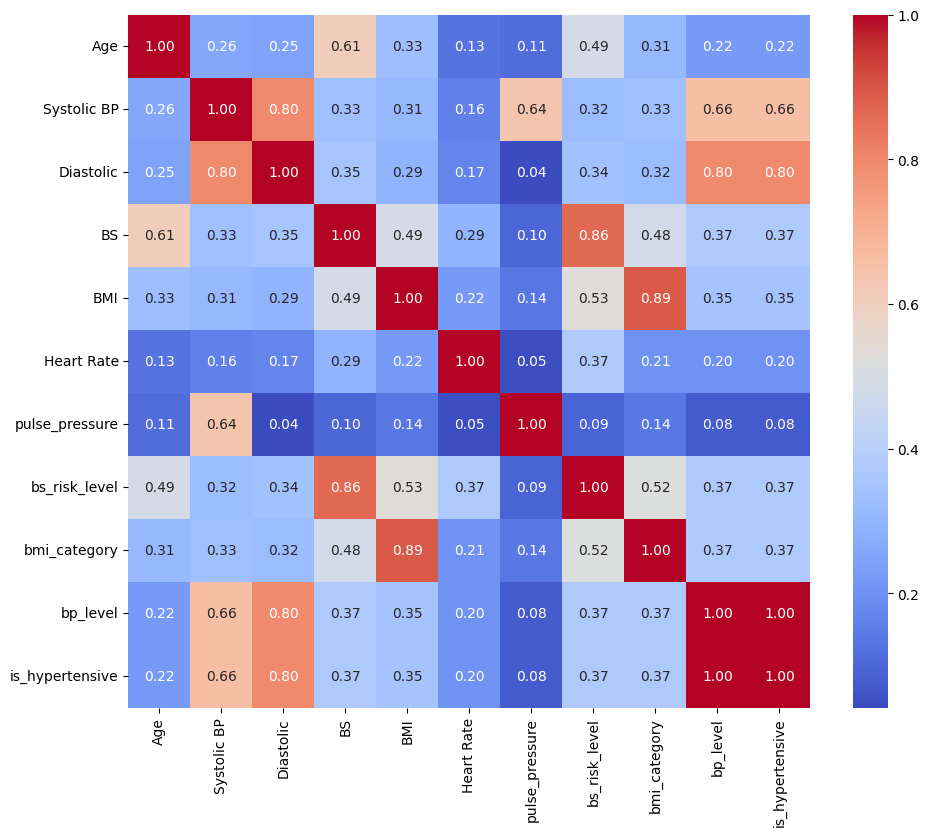

In [17]:
temp = selected_df.copy()

temp["bs_risk_level"] = temp["bs_risk_level"].map({
    "Normal": 0,
    "Borderline": 1,
    "Elevated": 2,
    "High": 3
})

temp["bmi_category"] = temp["bmi_category"].map({
    "Underweight": 0,
    "Normal": 1,
    "Overweight": 2,
    "Obese": 3
})

temp["bp_level"] = temp["bp_level"].map({
    "Normal": 0,
    "Hypertensive": 1
})

temp["is_hypertensive"] = temp["is_hypertensive"].astype(int)

correlation_column = [
    "Age", "Systolic BP", "Diastolic",
    "BS", "BMI", "Heart Rate", "pulse_pressure",
    "bs_risk_level","bmi_category", "bp_level", "is_hypertensive"
]

correlation = temp[correlation_column].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(
    data=correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()


### Data-quality interpretation

**If two features have a correlation above 0.85, which one do you remove?**

We have three correlations higher than 0.85:
- BMI & bmi_category => (I’m keeping both so I can use them according to the chosen model.)
- BS & bs_risk_level => (I keep the raw blood sugar data and delete the categorized version, because more information can be extracted from the raw data.)
- bp_level & is_hypertensive => (Since blood pressure is either normal or dangerous, I am removing the bp_level field.)



### Risk-factor interpretation

**Document your final decision regarding Gestational Diabetes and BMI-derived risk features: are they removed, kept, or kept with an explicit leakage note?**

The deployable model excludes leakage-prone features. `Gestational Diabetes` and BMI-derived risk flags are retained only in the leakage-inclusive comparison experiment to show how markedly performance can improve when post-diagnosis or same-pregnancy information is available. They are not part of the final no-leakage deployable model because they do not satisfy the prediction-time availability rule.


### Feature-level assessment

**Build the final reduced version of the dataset (`reduced_df`).**

In [18]:
reduced_df = selected_df.drop(columns=["bs_risk_level", "bp_level"]).copy()
reduced_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group,bmi_category,is_hypertensive,pulse_pressure,risk_factor_count
0,50,140.0,80.0,6.7,21.0,0.0,0.0,0,0,70.0,0.0,Advanced,Normal,True,60.0,2
1,17,110.0,60.0,3.4,23.0,0.0,0.0,0,0,72.0,0.0,Teen,Normal,False,50.0,1
2,48,120.0,80.0,11.0,27.9,1.0,1.0,0,0,88.0,1.0,Advanced,Overweight,False,40.0,4
3,24,180.0,120.0,9.0,29.0,0.0,1.0,0,0,76.0,1.0,Normal,Overweight,True,60.0,3
4,22,130.0,60.0,4.0,22.0,0.0,0.0,0,0,72.0,0.0,Normal,Normal,False,70.0,0


---

# Section 6: Data Transformation (Scaling)

### Risk summary

**Check whether the numeric features have very different scales.**

Yes, the numeric features live on very different scales.

In [19]:
check = reduced_df[numeric].agg(["min", "max", "mean", "std"]).T
check["range"] = check["max"] - check["min"]
check

,min,max,mean,std,range
Age,12.0,65.0,27.598501,9.165645,53.0
Systolic BP,70.0,180.0,116.896146,18.623445,110.0
Diastolic,40.0,140.0,77.093148,14.336819,100.0
BS,3.0,19.0,7.511595,3.044692,16.0
BMI,15.0,37.0,23.458458,3.846083,22.0
Heart Rate,58.0,92.0,75.828694,7.232073,34.0
pulse_pressure,10.0,90.0,39.802998,11.301659,80.0


### Analytical review**Compare which method (MinMax or Standardization) is more appropriate for this project, given the presence of real extreme values (not noise) in BS and BMI.**

Standardization is more appropriate here because minmax scaling would eliminate the BS and BMI data, which are not noise, whereas we did not completely remove the outliers because they are important.

In [20]:
numeric = ["Age", "Systolic BP", "Diastolic", "BS", "BMI", "Heart Rate", "pulse_pressure", "risk_factor_count"]
scaler = StandardScaler()
train_df[numeric] = scaler.fit_transform(train_df[numeric])
test_df[numeric] = scaler.transform(test_df[numeric])
reduced_df = train_df.drop(columns=["bs_risk_level", "bp_level"]).copy()
reduced_test_df = test_df.drop(columns=["bs_risk_level", "bp_level"]).copy()
selected_df = train_df
print("Scaler fit source: train_df")

Scaler fit source: train_df


---

# Section 7: Dataset Validation

### Additional analytical review

**Report a final data-quality checklist in a single table:**
- **Final shape of the dataset (rows/columns)** => (1166, 16)
- **Any remaining Nulls?** => 0
- **Any remaining duplicates?** => 0
- **Have medically implausible values been handled?** Yes
- **Is the format of all features appropriate?** Yes

In [21]:
reduced_df.shape

reduced_df.isnull().sum()

reduced_df.duplicated().sum()

np.int64(0)

### Additional interpretation

**Is the data suitable for KNN, Logistic Regression, and Decision Tree/Random Forest? Explain separately for each.**

- `KNN:` It is suitable for this algorithm because we standardized the data and equalized the scales; the distances are now consistent, so the results for Manhattan and Euclidean distances are not surprising.
- `Logistic Regression:` Scaling is appropriate, but the grouped data require coding.
- `Decision Tree/Random Forest:` It works effectively even without scaling and is suitable; standardization is not necessary for this model.

### Final data-understanding synthesis

**Save the final dataset:**
```python
pregnancy_prepared.csv
```

In [22]:
reduced_df_with_leakage = reduced_df.copy()
reduced_test_df_with_leakage = reduced_test_df.copy()
reduced_df_no_leakage = reduced_df.drop(columns=["Gestational Diabetes", "bmi_category", "risk_factor_count"]).copy()
reduced_test_df_no_leakage = reduced_test_df.drop(columns=["Gestational Diabetes", "bmi_category", "risk_factor_count"]).copy()

reduced_df_with_leakage.to_csv("../data/pregnancy_train_with_leakage_features.csv", index=False)
reduced_test_df_with_leakage.to_csv("../data/pregnancy_test_with_leakage_features.csv", index=False)
reduced_df_no_leakage.to_csv("../data/pregnancy_train_no_leakage_features.csv", index=False)
reduced_test_df_no_leakage.to_csv("../data/pregnancy_test_no_leakage_features.csv", index=False)
reduced_df.to_csv("../data/pregnancy_prepared.csv", index=False)

### Analytical review**Explain why the pipeline was reordered so that Train/Test split happens before imputation, feature engineering, and scaling. Name specifically which three operations previously caused data leakage and why.**

The split now precedes imputation, feature engineering, and scaling. Previously, full-dataset medians, target-derived risk features, and StandardScaler mean/variance values included future test observations, making test performance optimistic.

### Analytical review**Confirm that the BMI imputation medians and StandardScaler statistics were computed only from the training set. Show the code that proves this.**

In [23]:
print("BMI medians were fit from train_df:", bmi_median_by_risk.to_dict())
print("Scaler fit source: train_df only")
assert set(bmi_median_by_risk.index) <= set(train_df["Risk Level"].unique())
assert hasattr(scaler, "mean_") and len(scaler.mean_) == len(numeric)

BMI medians were fit from train_df: {0.0: 22.0, 1.0: 26.0}
Scaler fit source: train_df only


### Analytical review**Train a simple baseline model with and without risk_factor_count using the same split and compare Accuracy and High-risk Recall.**

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

baseline_features = [c for c in numeric if c != "risk_factor_count"]
X_train_with = train_df[numeric]
X_test_with = test_df[numeric]
X_train_without = train_df[baseline_features]
X_test_without = test_df[baseline_features]
y_train = train_df["Risk Level"].astype(int)
y_test = test_df["Risk Level"].astype(int)

baseline_results = []
for name, Xtr, Xte in [("With risk_factor_count", X_train_with, X_test_with), ("Without risk_factor_count", X_train_without, X_test_without)]:
    model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    baseline_results.append({"Version": name, "Accuracy": accuracy_score(y_test, pred), "Recall (High-risk)": recall_score(y_test, pred, pos_label=1)})
pd.DataFrame(baseline_results)

,Version,Accuracy,Recall (High-risk)
0,With risk_factor_count,0.924051,0.947368
1,Without risk_factor_count,0.869198,0.821053


### Analytical review**Build and save parallel final datasets with leakage-prone features and without them.**

In [25]:
print("With leakage-prone features:", reduced_df_with_leakage.shape, reduced_test_df_with_leakage.shape)
print("Without leakage-prone features:", reduced_df_no_leakage.shape, reduced_test_df_no_leakage.shape)
print("Saved four train/test CSV files for Modeling.ipynb.")

With leakage-prone features: (934, 16) (237, 16)
Without leakage-prone features: (934, 13) (237, 13)
Saved four train/test CSV files for Modeling.ipynb.


### Analytical review**Reimplement median imputation and StandardScaler with sklearn Pipeline and ColumnTransformer so fitting is structurally restricted to training data.**

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

pipeline_numeric = ["Systolic BP", "Diastolic", "BS", "BMI", "Heart Rate"]
preparation_pipeline = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), pipeline_numeric),
], remainder="passthrough")
preparation_pipeline.fit(train_df[pipeline_numeric])
print(preparation_pipeline)

ColumnTransformer(remainder='passthrough',
                  transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Systolic BP', 'Diastolic', 'BS', 'BMI',
                                  'Heart Rate'])])
